# Token embeddings and tied output weights

A language model can use one matrix both to look up tokens and to score the next token. Six symbols arranged on a ring give us a transition law we can check exactly.

Each symbol can stay, step clockwise or step anticlockwise. A learned projection between the lookup and the output gives a tied model room to learn asymmetric transitions. Both models see the same transition counts.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def report(columns, rows):
    frame = pd.DataFrame(rows, columns=columns)
    try:
        from IPython import get_ipython

        interactive = get_ipython() is not None
    except ImportError:
        interactive = False
    if interactive:
        from IPython.display import display

        display(frame.round(5))
    else:
        print(frame.round(5).to_string(index=False))


import torch
import torch.nn.functional as F
from torch import nn


def seed():
    torch.manual_seed(17)
    torch.set_num_threads(1)

## Form a controlled next-token problem

Each row is an empirical distribution over the six possible successors. The independent test sample uses the same law.

In [2]:
seed()
vocab = 6
law = np.zeros((vocab, vocab))
for i in range(vocab):
    law[i, [i, (i + 1) % vocab, (i - 1) % vocab]] = [0.15, 0.65, 0.20]


def sample_counts(seed_value, n):
    rng = np.random.default_rng(seed_value)
    return torch.tensor(np.stack([rng.multinomial(n, p) for p in law]), dtype=torch.float32)


train, test = sample_counts(23, 180), sample_counts(79, 160)

## Fit the transition tables

Optimise multinomial cross-entropy on training counts. Test loss weights each observed transition by its frequency.

In [3]:
rows = []
learned = []
for tied in (True, False):
    torch.manual_seed(17)
    emb = nn.Embedding(vocab, 5)
    projection = nn.Linear(5, 5, bias=False)
    head = nn.Linear(5, vocab, bias=False)
    if tied:
        head.weight = emb.weight
    model = nn.Sequential(emb, projection, head)
    opt = torch.optim.Adam(model.parameters(), lr=0.045)
    for _ in range(240):
        logp = model(torch.arange(vocab)).log_softmax(-1)
        loss = -(train * logp).sum() / train.sum()
        opt.zero_grad()
        loss.backward()
        opt.step()
    with torch.no_grad():
        logp = model(torch.arange(vocab)).log_softmax(-1)
        nll = float(-(test * logp).sum() / test.sum())
        learned.append(logp.exp().numpy())
        rows.append(
            (
                "Tied" if tied else "Separate",
                sum(p.numel() for p in model.parameters()),
                nll,
                np.exp(nll),
            )
        )
report(["Output weights", "Parameters", "Test NLL (nats)", "Perplexity"], rows)

,Output weights,Parameters,Test NLL (nats),Perplexity
0,Tied,55,0.87676,2.40309
1,Separate,85,0.87667,2.40287


## Read a row of the fitted model

The bright off-diagonal band follows the clockwise successor. The colour scale is shared across panels.

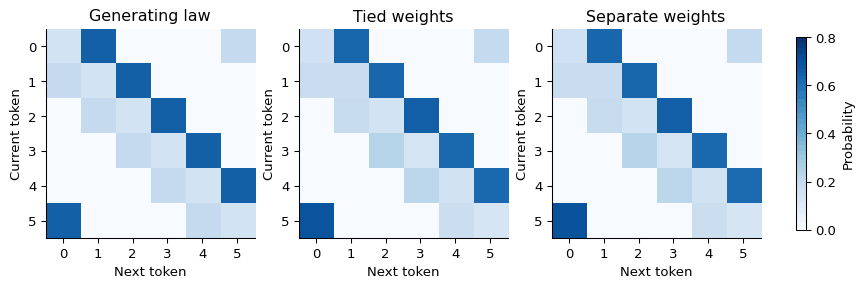

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(9, 3), layout="constrained")
for ax, m, title in zip(
    axes, [law, *learned], ["Generating law", "Tied weights", "Separate weights"]
):
    im = ax.imshow(m, vmin=0, vmax=0.8, cmap="Blues")
    ax.set(
        title=title,
        xlabel="Next token",
        ylabel="Current token",
        xticks=range(vocab),
        yticks=range(vocab),
    )
fig.colorbar(im, ax=axes, label="Probability", shrink=0.75)
plt.show()

## Interpreting the result

Tying the weights reduced the parameter count from 85 to 55. Both models produced test perplexity of about 2.40 on the independently sampled transitions.

The table counts unique trainable parameters. Reusing a tensor saves one vocabulary matrix. On a six-symbol task, held-out perplexity also depends on the finite sample of transitions.

## Exercise

Remove the projection and check which transition patterns a symmetric dot-product score can represent.

## References

[Vaswani et al. (2017), Attention Is All You Need](https://arxiv.org/abs/1706.03762)

[Inan, Khosravi and Socher (2017), Tying Word Vectors and Word Classifiers](https://arxiv.org/abs/1611.01462)